hw 8
=========

In [1]:
# Standard library
import os
import time
from IPython.display import display, HTML

# Environment settings (before importing TensorFlow)
os.environ["PYTHONHASHSEED"] = "42"
os.environ["TF_DETERMINISTIC_OPS"] = "1"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

# Data and plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

# TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, LSTM, GRU, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping

# Reproducibility
random_seed = 42
tf.keras.utils.set_random_seed(random_seed)

# Convenience
def format_hms(seconds):
    """Format elapsed seconds as H:MM:SS."""
    return time.strftime("%H:%M:%S", time.gmtime(seconds))

print("TensorFlow version:", tf.__version__)
print("Visible GPUs:", tf.config.get_visible_devices("GPU"))


TensorFlow version: 2.21.0
Visible GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


---

# 0 premade functions

In [ ]:
results = {}

In [3]:
def plot_learning_curves_scaled(history, title="Learning Curves", verbose=True, plot=True):
    """Plot MAE in scaled units and record metrics at minimum validation MSE."""
    H = history.history if hasattr(history, "history") else history

    required = ("loss", "val_loss", "mae", "val_mae")
    missing = [key for key in required if key not in H]
    if missing:
        raise ValueError(f"Missing history metrics: {missing}")

    val_loss = np.asarray(H["val_loss"])
    mae = np.asarray(H["mae"])
    val_mae = np.asarray(H["val_mae"])
    epochs = np.arange(1, len(mae) + 1)

    # Select epoch by minimum validation MSE (not minimum MAE)
    best_idx = int(np.argmin(val_loss))
    best_epoch = best_idx + 1

    # Record MAE at the selected epoch
    summary = {
        "selected_epoch": best_epoch,
        "val_mae_at_min_valloss": float(val_mae[best_idx]),
        "train_mae_at_sel": float(mae[best_idx]),
        "val_loss": float(val_loss[best_idx]),
        "units": "scaled"
    }
    results[title] = summary

    # Plot training and validation MAE
    if plot:
        fig, ax = plt.subplots(figsize=(9, 5))

        ax.plot(epochs, mae, label="Training MAE")
        ax.plot(epochs, val_mae, label="Validation MAE")

        ax.axvline(
            best_epoch,
            color="gray",
            linestyle=":",
            label=f"Selected epoch = {best_epoch} (min val_loss)"
        )

        ax.set_title(title)
        ax.set_xlabel("Epoch")
        ax.set_ylabel("MAE (scaled units)")
        ax.grid(True, linestyle=":", alpha=0.5)
        ax.legend()

        plt.tight_layout()
        plt.show()

    if verbose:
        print(f"Selected epoch: {best_epoch} (minimum validation MSE)")
        print(f"Training MAE:   {summary['train_mae_at_sel']:.4f}")
        print(f"Validation MAE: {summary['val_mae_at_min_valloss']:.4f}")

    return summary


In [4]:
def print_results(sort_by="val_mae_at_min_valloss"):

    """Display experiments ranked by validation MAE at the selected epoch."""

    if not results:
        print("No results recorded yet.")
        return

    print(f"{'Experiment':<35} {'Val MAE':>12} {'Epoch':>8}")
    print("-" * 58)

    for name, info in sorted(
        results.items(),
        key=lambda item: item[1][sort_by]
    ):
        print(
            f"{name:<35} "
            f"{info['val_mae_at_min_valloss']:>12.4f} "
            f"{info['selected_epoch']:>8}"
        )

    print("\nMAE is in scaled units; epoch selected by minimum validation MSE.")


In [5]:
def train_and_validate(
    model,
    X_train=None, y_train=None,
    X_val=None, y_val=None,
    *,
    epochs=50,
    batch_size=64,
    optimizer="Adam",
    lr_schedule=1e-3,
    clipnorm=1.0,
    patience=5,
    callbacks=None,
    title="LSTM Experiment",
    verbose=0,
    plot_scaled_curves=True,
    return_history=False
):
    """Train and validate regression model; return summary or (history, summary)."""
    g = globals()
    X_train = X_train if X_train is not None else g.get("X_train")
    y_train = y_train if y_train is not None else g.get("y_train")
    X_val = X_val if X_val is not None else g.get("X_val")
    y_val = y_val if y_val is not None else g.get("y_val")

    if any(x is None for x in (X_train, y_train, X_val, y_val)):
        raise ValueError("Training and validation datasets are required.")

    if isinstance(optimizer, str):
        opt = getattr(keras.optimizers, optimizer)(
            learning_rate=lr_schedule, clipnorm=clipnorm
        )
    else:
        opt = optimizer

    model.compile(
        optimizer=opt,
        loss="mse",
        metrics=[
            keras.metrics.MeanAbsoluteError(name="mae")
        ]
    )

    early_stop = EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=patience,
        min_delta=0.0,
        restore_best_weights=True
    )
    cb = [early_stop] + ([] if callbacks is None else list(callbacks))

    # print(f"\n{title}\n")

    display(HTML(f""" 
    <h2 style="
        font-family: 'Poppins', sans-serif;
        font-size: 2rem;
        font-weight: 700;
        margin-top: 2em;
        color: #0057ff;
        background: rgba(0,87,255,0.06);
        padding: 0.5em 0.8em;
        border-radius: 8px;">
        {title}
        </h2>"""))

    start = time.time()
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=cb,
        shuffle=True,
        verbose=verbose
    )
    elapsed = time.time() - start

    summary = plot_learning_curves_scaled(
        history, title=title, plot=plot_scaled_curves
    )
    summary["elapsed_sec"] = elapsed
    print(f"Training time: {format_hms(elapsed)}")

    if return_history:
        return history, summary
    return summary


In [6]:
def make_windows(arr, lookback, horizon):
    """Return X (samples, lookback, 1), y (samples, horizon)."""
    if lookback < 1 or horizon < 1:
        raise ValueError("lookback and horizon must be positive.")
    if len(arr) < lookback + horizon:
        raise ValueError("Not enough observations for these windows.")

    X, y = [], []
    for i in range(lookback, len(arr) - horizon + 1):
        X.append(arr[i-lookback:i, 0])
        y.append(arr[i:i+horizon, 0])
    X = np.asarray(X, dtype=np.float32)
    y = np.asarray(y, dtype=np.float32)
    return X[..., None], y


In [7]:
def build_datasets(lookback=168, horizon=1):
    """Create chronological train/validation/test windows with past-only context."""
    X_tr, y_tr = make_windows(train_x, lookback, horizon)

    val_context = np.concatenate([train_x[-lookback:], val_x], axis=0)
    X_va, y_va = make_windows(val_context, lookback, horizon)

    previous = np.concatenate([train_x, val_x], axis=0)
    test_context = np.concatenate([previous[-lookback:], test_x], axis=0)
    X_te, y_te = make_windows(test_context, lookback, horizon)
    return X_tr, y_tr, X_va, y_va, X_te, y_te

In [8]:
def make_baseline_model(lookback, horizon):
    """Construct the baseline LSTM architecture."""
    return Sequential([
        Input(shape=(lookback, 1)),
        LSTM(32),
        Dropout(0.2),
        Dense(16, activation="relu",
              kernel_initializer=keras.initializers.HeNormal(seed=random_seed)),
        Dense(horizon)
    ])

In [9]:
def evaluate_forecast(
    model, X, y,
    *,
    title="Validation",
    target_scaler=None,
    datetime_index=None,
    plot_last_hours=24*7
):
    """Evaluate direct forecasts using MAE; average overlaps for plotting."""

    y_pred = np.asarray(model.predict(X, verbose=0))
    y_true = np.asarray(y)

    if y_pred.ndim == 1:
        y_pred = y_pred[:, None]
    if y_true.ndim == 1:
        y_true = y_true[:, None]

    if y_pred.shape != y_true.shape:
        raise ValueError(
            f"Shape mismatch: predictions {y_pred.shape}, "
            f"targets {y_true.shape}"
        )

    H = y_pred.shape[1]

    # Convert from scaled values to original units
    def convert_units(arr):
        if target_scaler is None:
            return arr
        original_shape = arr.shape
        converted = target_scaler.inverse_transform(
            arr.reshape(-1, 1)
        )
        return converted.reshape(original_shape)

    y_pred_u = convert_units(y_pred)
    y_true_u = convert_units(y_true)

    units = "MW" if target_scaler is not None else "scaled"

    # Overall MAE, computed before averaging overlapping predictions
    errors = y_pred_u - y_true_u
    mae = float(np.mean(np.abs(errors)))

    print(f"{title} MAE: {mae:.2f} {units}")

    # MAE at each forecast horizon
    mae_by_step = np.mean(np.abs(errors), axis=0)

    if H > 1:
        print("\nMAE by forecast step:")
        for h in range(H):
            print(f"  Hour {h+1:2d}: MAE = {mae_by_step[h]:.2f} {units}")

    # Average overlapping forecasts to produce one continuous timeline
    def stitch_predictions(arr):
        n, horizon = arr.shape
        total = n + horizon - 1

        sums = np.zeros(total)
        counts = np.zeros(total)

        for i in range(n):
            sums[i:i+horizon] += arr[i]
            counts[i:i+horizon] += 1

        return sums / counts

    true_timeline = stitch_predictions(y_true_u)
    pred_timeline = stitch_predictions(y_pred_u)

    N = min(plot_last_hours, len(true_timeline))

    if datetime_index is not None:
        if len(datetime_index) != len(true_timeline):
            raise ValueError("Datetime index length does not match forecast.")
        x_axis = datetime_index[-N:]
    else:
        x_axis = np.arange(len(true_timeline) - N, len(true_timeline))

    # Plot
    fig, ax = plt.subplots(figsize=(14, 5))

    ax.plot(
        x_axis,
        true_timeline[-N:],
        label="Actual"
    )

    ax.plot(
        x_axis,
        pred_timeline[-N:],
        linestyle="--",
        label="Predicted"
    )

    ax.set_title(f"{title} — Last {N} Hours")
    ax.set_xlabel("Date" if datetime_index is not None else "Hour")
    ax.set_ylabel(f"Electricity Demand ({units})")
    ax.grid(True, axis="y", linestyle=":", alpha=0.5)
    ax.legend()

    if datetime_index is not None:
        fig.autofmt_xdate()

    plt.tight_layout()
    plt.show()

    return {
        "mae": mae,
        "mae_by_step": mae_by_step
    }


---

## 0 data

In [10]:
# Load NYISO hourly electricity demand
url = "https://www.cs.bu.edu/fac/snyder/cs505/Data/nyiso_loads.csv"
df = pd.read_csv(url)

# Columns Hr1 through Hr24
hour_cols = [f"Hr{i}" for i in range(1, 25)]
if not set(hour_cols).issubset(df.columns):
    raise ValueError("Expected hourly columns Hr1 through Hr24.")



### explore

Data period: 2025-01-01 00:00:00 to 2025-05-31 23:00:00
Total hours: 3624
Training:    2536
Validation:  543
Testing:     545


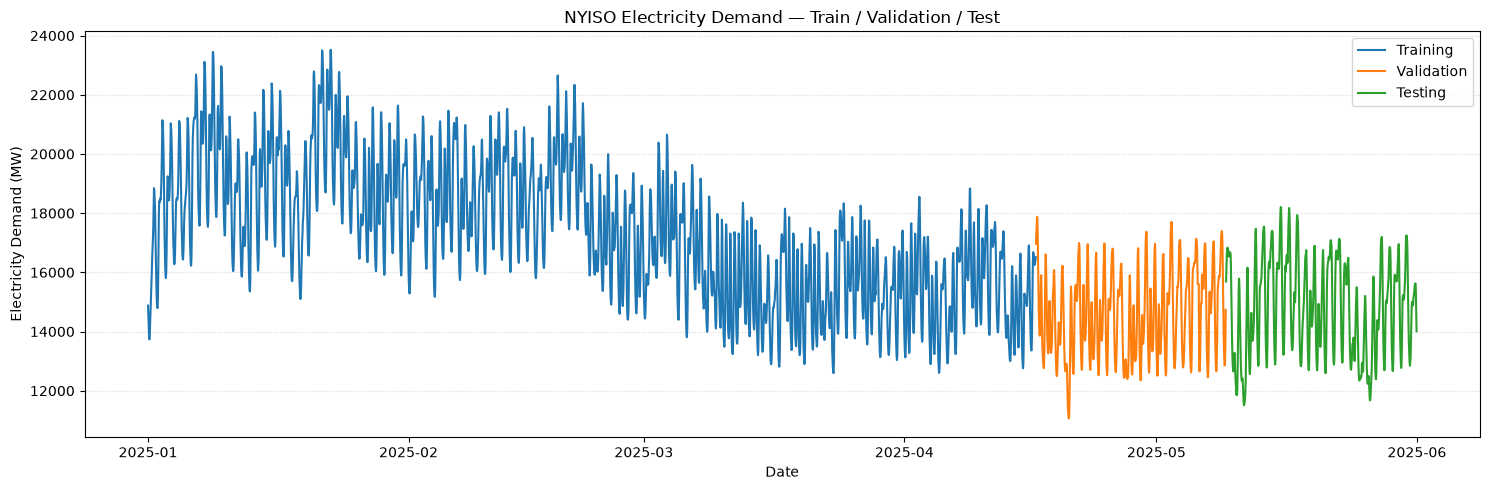

In [11]:
# Convert wide format to one row per hour
long_df = df.melt(
    id_vars=["Year", "Month", "Day"],
    value_vars=hour_cols,
    var_name="Hour",
    value_name="Load"
)

# Construct hourly timestamps
hour_number = long_df["Hour"].str[2:].astype(int)
long_df["Datetime"] = (
    pd.to_datetime(long_df[["Year", "Month", "Day"]])
    + pd.to_timedelta(hour_number - 1, unit="h")
)
long_df = long_df.sort_values("Datetime")

load_series = pd.Series(
    pd.to_numeric(long_df["Load"], errors="coerce").to_numpy(),
    index=long_df["Datetime"],
    name="NYISO_Load"
)

# Keep the first five calendar months
start = load_series.index.min().normalize()
end = start + pd.DateOffset(months=5)
s5 = load_series.loc[
    (load_series.index >= start) & (load_series.index < end)
].copy()

# Enforce hourly frequency and fill short gaps
s5 = s5.asfreq("h")
s5 = s5.interpolate(method="time", limit=3)
if s5.isna().any():
    raise ValueError("Missing observations remain after interpolation. Inspect the data before continuing.")

# Chronological 70/15/15 split
N = len(s5)
n_train = int(0.70 * N)
n_val = int(0.15 * N)
n_test = N - n_train - n_val

train = s5.iloc[:n_train]
val = s5.iloc[n_train:n_train + n_val]
test = s5.iloc[n_train + n_val:]

print(f"Data period: {s5.index[0]} to {s5.index[-1]}")
print(f"Total hours: {N}")
print(f"Training:    {len(train)}")
print(f"Validation:  {len(val)}")
print(f"Testing:     {len(test)}")

# Plot chronological split
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(train.index, train.values, label="Training")
ax.plot(val.index, val.values, label="Validation")
ax.plot(test.index, test.values, label="Testing")
ax.set_title("NYISO Electricity Demand — Train / Validation / Test")
ax.set_xlabel("Date")
ax.set_ylabel("Electricity Demand (MW)")
ax.grid(True, axis="y", linestyle=":", alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()


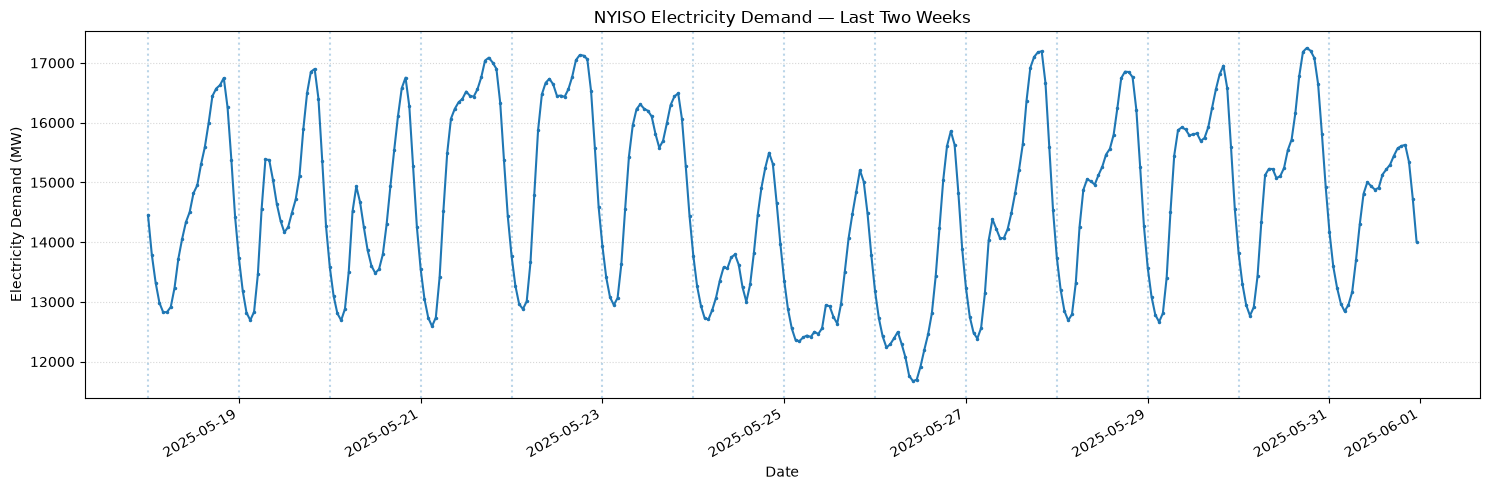

In [12]:
# Examine daily and weekly demand patterns
last_two_weeks = s5.tail(24 * 14)
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(last_two_weeks.index, last_two_weeks.values, marker=".", markersize=3)

# Mark midnight at the start of each day
for day in pd.date_range(
    last_two_weeks.index[0].normalize(),
    last_two_weeks.index[-1].normalize(),
    freq="D"
):
    ax.axvline(day, linestyle=":", alpha=0.3)

ax.set_title("NYISO Electricity Demand — Last Two Weeks")
ax.set_xlabel("Date")
ax.set_ylabel("Electricity Demand (MW)")
ax.grid(True, axis="y", linestyle=":", alpha=0.5)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


In [13]:
# Scale using training data only
scaler = StandardScaler()
train_x = scaler.fit_transform(train.to_numpy().reshape(-1, 1)).astype(np.float32)
val_x = scaler.transform(val.to_numpy().reshape(-1, 1)).astype(np.float32)
test_x = scaler.transform(test.to_numpy().reshape(-1, 1)).astype(np.float32)


## baseline


In [14]:
# Baseline configuration
lookback = 24 * 7
horizon = 1
X_train, y_train, X_val, y_val, X_test, y_test = build_datasets(lookback, horizon)

print("Dataset shapes:")
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val:  ", X_val.shape, "y_val:  ", y_val.shape)
print("X_test: ", X_test.shape, "y_test:", y_test.shape)


Dataset shapes:
X_train: (2368, 168, 1) y_train: (2368, 1)
X_val:   (543, 168, 1) y_val:   (543, 1)
X_test:  (545, 168, 1) y_test: (545, 1)


E0000 00:00:1792773420.484452    1267 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


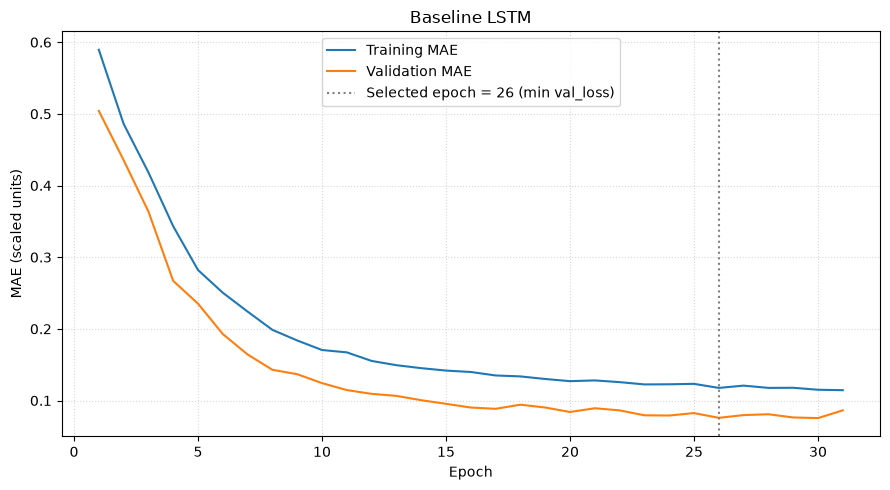

Selected epoch: 26 (minimum validation MSE)
Training MAE:   0.1176
Validation MAE: 0.0759
Training time: 00:00:32


In [15]:
# Establish reproducible baseline initialization
tf.keras.utils.set_random_seed(random_seed)
baseline_model = make_baseline_model(lookback, horizon)

# Preserve baseline configuration and datasets
baseline_lookback = lookback
baseline_horizon = horizon
baseline_X_val, baseline_y_val = X_val, y_val
baseline_X_test, baseline_y_test = X_test, y_test

baseline_history, baseline_info = train_and_validate(
    baseline_model, title="Baseline LSTM", verbose=0, return_history=True
)


E0000 00:00:1792773448.774737    1267 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


Baseline Validation MAE: 176.16 MW


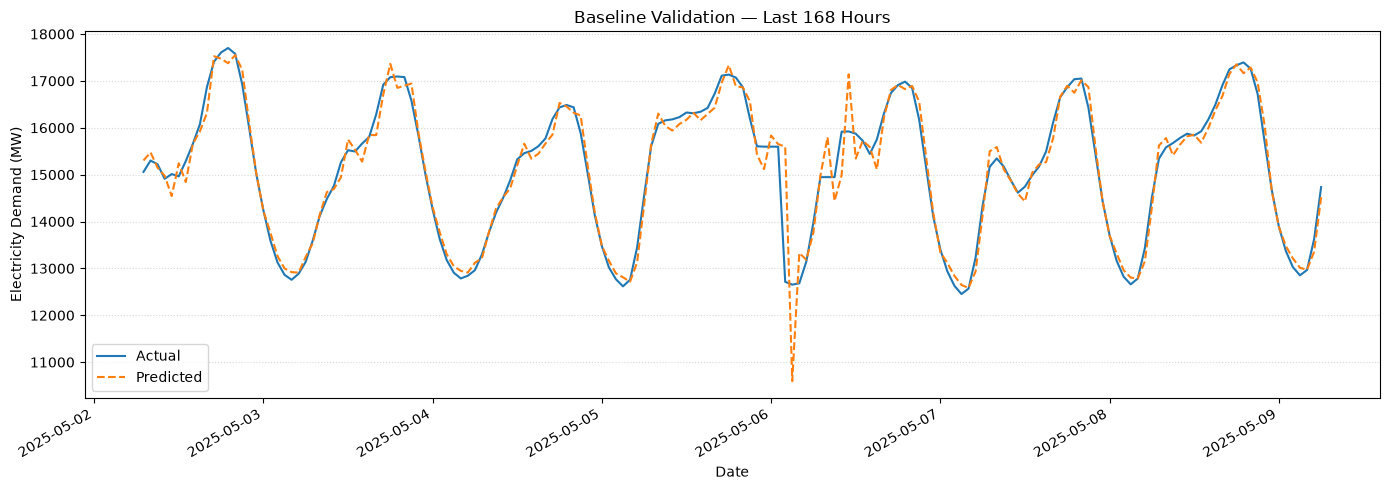


Experiment summary:
Experiment                               Val MAE    Epoch
----------------------------------------------------------
Baseline LSTM                             0.0759       26

MAE is in scaled units; epoch selected by minimum validation MSE.


In [16]:
# Evaluate baseline on validation data
baseline_validation = evaluate_forecast(
    baseline_model,
    baseline_X_val,
    baseline_y_val,
    title="Baseline Validation",
    target_scaler=scaler,
    datetime_index=val.index,
    plot_last_hours=24*7
)

print("\nExperiment summary:")
print_results()

In [17]:
results

{'Baseline LSTM': {'selected_epoch': 26,
  'val_mae_at_min_valloss': 0.07585766911506653,
  'train_mae_at_sel': 0.11760718375444412,
  'val_loss': 0.01349978893995285,
  'units': 'scaled',
  'elapsed_sec': 32.34852886199951}}

In [18]:
baseline_info

{'selected_epoch': 26,
 'val_mae_at_min_valloss': 0.07585766911506653,
 'train_mae_at_sel': 0.11760718375444412,
 'val_loss': 0.01349978893995285,
 'units': 'scaled',
 'elapsed_sec': 32.34852886199951}

---

# p1

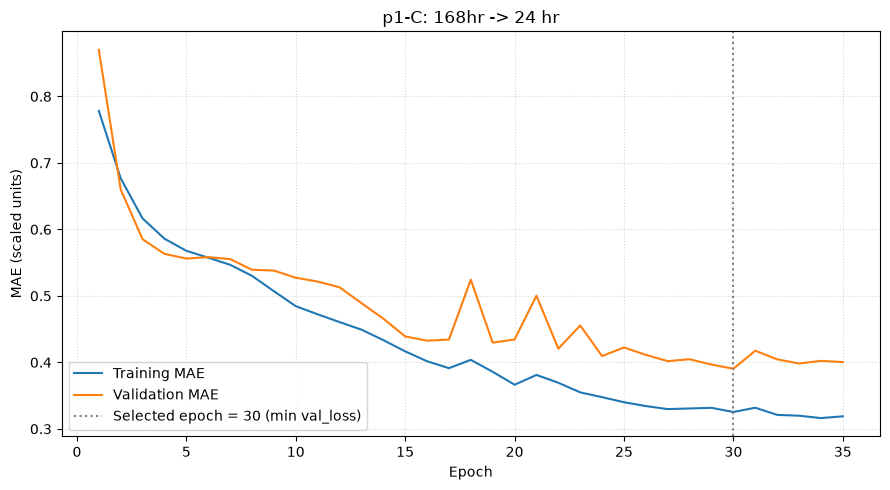

Selected epoch: 30 (minimum validation MSE)
Training MAE:   0.3253
Validation MAE: 0.3904
Training time: 00:00:36


E0000 00:00:1792773485.767276    1267 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


p1-C: 168hr -> 24 hr MAE: 906.71 MW

MAE by forecast step:
  Hour  1: MAE = 704.79 MW
  Hour  2: MAE = 871.09 MW
  Hour  3: MAE = 856.71 MW
  Hour  4: MAE = 945.61 MW
  Hour  5: MAE = 973.09 MW
  Hour  6: MAE = 925.72 MW
  Hour  7: MAE = 941.94 MW
  Hour  8: MAE = 1011.95 MW
  Hour  9: MAE = 971.70 MW
  Hour 10: MAE = 904.04 MW
  Hour 11: MAE = 972.96 MW
  Hour 12: MAE = 947.58 MW
  Hour 13: MAE = 902.65 MW
  Hour 14: MAE = 933.41 MW
  Hour 15: MAE = 894.96 MW
  Hour 16: MAE = 919.58 MW
  Hour 17: MAE = 955.10 MW
  Hour 18: MAE = 869.56 MW
  Hour 19: MAE = 906.00 MW
  Hour 20: MAE = 935.51 MW
  Hour 21: MAE = 892.96 MW
  Hour 22: MAE = 852.87 MW
  Hour 23: MAE = 852.77 MW
  Hour 24: MAE = 818.41 MW


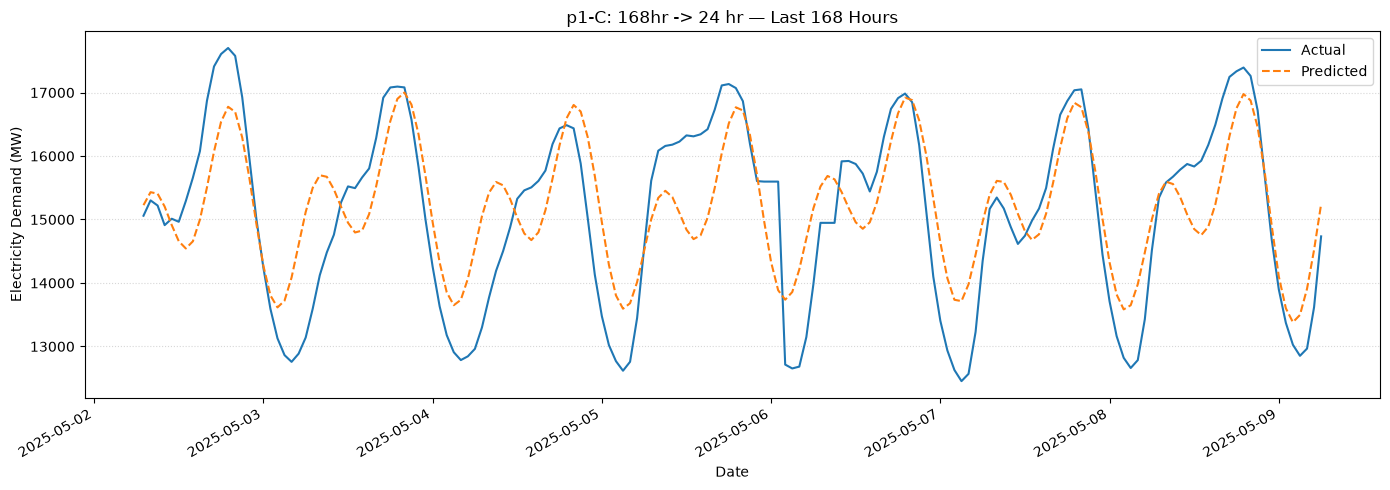

In [19]:
p1_experiment_config = {
    "p1-A: 24hr -> 1 hr"    : dict(lookback = 24*1  , horizon = 1),
    "p1-B: 336hr -> 1 hr"   : dict(lookback = 24*14 , horizon = 1),
    "p1-C: 168hr -> 24 hr"  : dict(lookback = 24*7  , horizon = 24),
}


for p1_title, p1_cfg in p1_experiment_config.items():
    lookback_horizon_config = {l:h for l,h in p1_cfg.items()}
    X_train, y_train, X_val, y_val, X_test, y_test = build_datasets(**lookback_horizon_config)

    p1_experiment_model = make_baseline_model(**lookback_horizon_config)
    p1_info = train_and_validate(
        model =     p1_experiment_model,
        title =     p1_title, 
        verbose=    0, 
        return_history=False
    )

    evaluate_forecast(
        p1_experiment_model,
        X_val,
        y_val,
        title=      p1_title,
        target_scaler=scaler,
        datetime_index=val.index,
        plot_last_hours=24*7
    )

    print("=="*80)





In [20]:
print("\nExperiment summary:")
print_results()


Experiment summary:
Experiment                               Val MAE    Epoch
----------------------------------------------------------
Baseline LSTM                             0.0759       26
p1-C: 168hr -> 24 hr                      0.3904       30

MAE is in scaled units; epoch selected by minimum validation MSE.


---

# p2

In [21]:
from keras import layers

E0000 00:00:1792776698.157849    1267 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


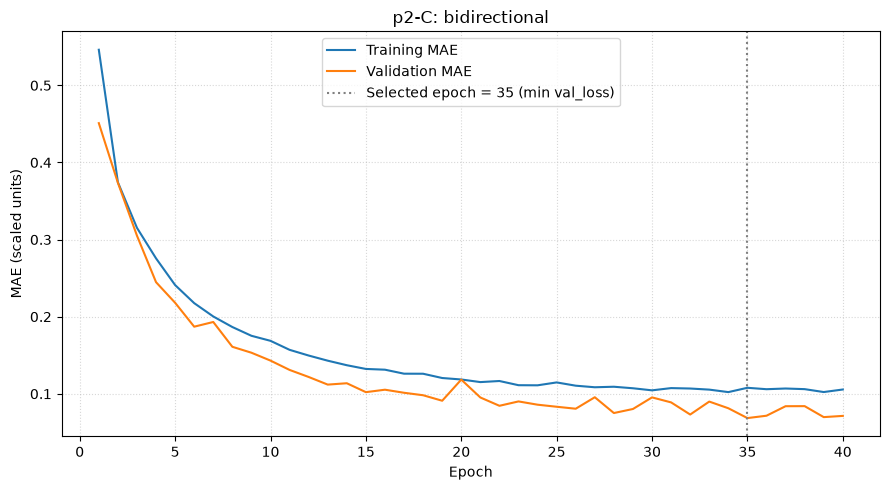

Selected epoch: 35 (minimum validation MSE)
Training MAE:   0.1078
Validation MAE: 0.0685
Training time: 00:00:55


E0000 00:00:1792776750.918606    1267 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


p2-C: bidirectional MAE: 159.06 MW


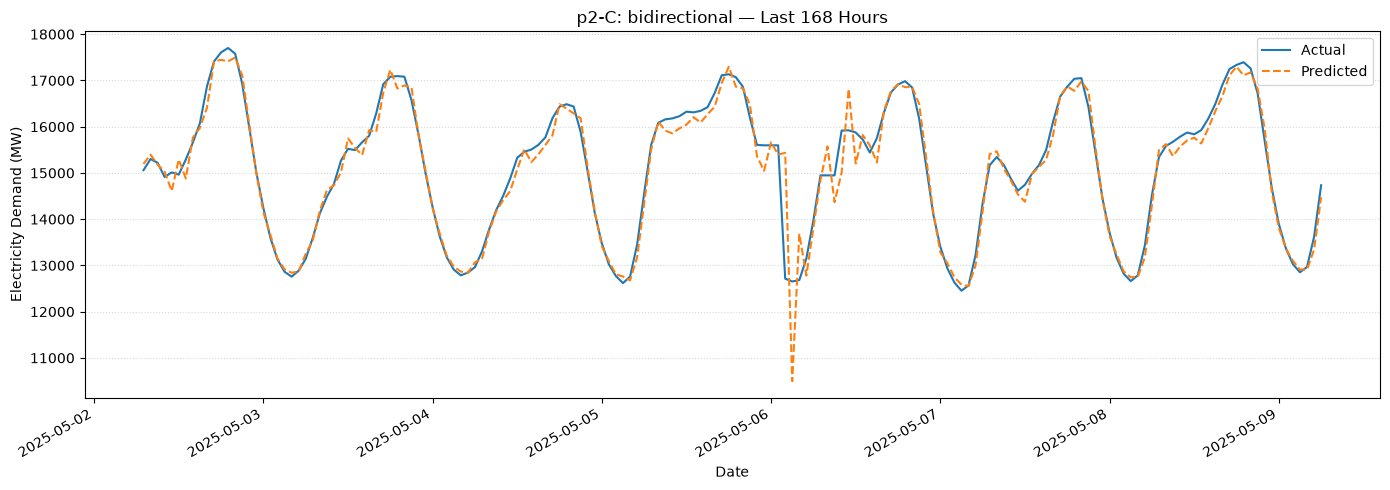

In [25]:
p2_experiment_config = {
    # "p2-A: 2nd dense": dict(
    #     lookback=   24 * 7,
    #     horizon=    1,
    #     layers=[
    #             ("LSTM", dict(units=32)),
    #             ("Dropout", dict(rate=0.2)),
    #             ("Dense", dict(units=32,activation="relu",kernel_initializer="he_normal",)),
    #             ("Dense", dict(units=16,activation="relu",kernel_initializer="he_normal",)),
    #             ],
    #     output=dict(),
    # ),

    # "p2-B: stacked LSTM": dict(
    #     lookback=   24 * 7,
    #     horizon=    1,
    #     layers=[
    #             ("LSTM", dict(units=32, return_sequences=True)),
    #             ("LSTM", dict(units=32, return_sequences=False)),
    #             ("Dropout", dict(rate=0.2)),
    #             ("Dense", dict(units=16,activation="relu",kernel_initializer="he_normal",)),
    #             ],
    #     output=dict(),
    # ),

    "p2-C: bidirectional": dict(
        lookback=   24 * 7,
        horizon=    1,
        layers=[
                ("LSTM", dict(units=32, bidirectional=True)),
                ("Dropout", dict(rate=0.2)),
                ("Dense", dict(units=16,activation="relu",kernel_initializer="he_normal",)),
                ],
        output=dict(),
    ),

}



def make_experiment_model(lookback, horizon, layer_config, output_config, collapse="flatten"):
    model = keras.Sequential([
        keras.Input(shape=(lookback, 1)),
    ])

    for layer_name, layer_kwargs in layer_config:
        kwargs = layer_kwargs.copy()
        bidirectional = kwargs.pop("bidirectional", False)

        layer = getattr(layers, layer_name)(**kwargs)
        if bidirectional:
            layer = layers.Bidirectional(layer)

        model.add(layer)

    ## _If time axis is still present (rank 3), collapse it before the output head
    if len(model.output_shape) == 3:
        if collapse == "flatten":
            model.add(layers.Flatten())
        elif collapse == "avg":
            model.add(layers.GlobalAveragePooling1D())
        elif collapse == "last":
            model.add(layers.Lambda(lambda t: t[:, -1, :]))

    model.add(layers.Dense(units=horizon, **output_config))

    return model



p2_results = {}

for p2_title, p2_cfg in p2_experiment_config.items():
    keras.backend.clear_session()
    keras.utils.set_random_seed(random_seed)

    lookback_horizon_config = {
                key: p2_cfg[key]
                for key in ("lookback", "horizon")
            }

    X_train, y_train, X_val, y_val, X_test, y_test = build_datasets(**lookback_horizon_config)

    p2_experiment_model = make_experiment_model(
        **lookback_horizon_config,
        layer_config=p2_cfg["layers"],
        output_config=p2_cfg["output"],
    )

    p2_info = train_and_validate(
        model=p2_experiment_model,
        title=p2_title,
        verbose=0,
        return_history=False,
    )

    evaluate_forecast(
        p2_experiment_model,
        X_val,
        y_val,
        title=p2_title,
        target_scaler=scaler,
        datetime_index=val.index,
        plot_last_hours=24 * 7,
    )

    p2_results[p2_title] = dict(
        config=p2_cfg,
        info=p2_info,
    )

    print("==" * 80)

In [26]:
p2_results

{'p2-C: bidirectional': {'config': {'lookback': 168,
   'horizon': 1,
   'layers': [('LSTM', {'units': 32, 'bidirectional': True}),
    ('Dropout', {'rate': 0.2}),
    ('Dense',
     {'units': 16, 'activation': 'relu', 'kernel_initializer': 'he_normal'})],
   'output': {}},
  'info': {'selected_epoch': 35,
   'val_mae_at_min_valloss': 0.06849215924739838,
   'train_mae_at_sel': 0.10777279734611511,
   'val_loss': 0.011926580220460892,
   'units': 'scaled',
   'elapsed_sec': 55.810054779052734}}}

---

# p3

In [63]:
results2 = {}

E0000 00:00:1792786955.458159    1267 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


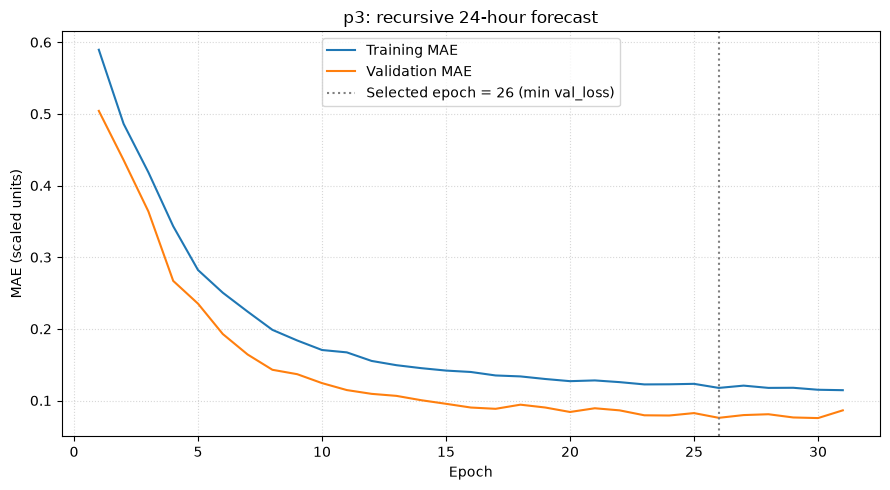

Selected epoch: 26 (minimum validation MSE)
Training MAE:   0.1176
Validation MAE: 0.0759
Training time: 00:00:29


E0000 00:00:1792786983.082450    1267 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_15}}


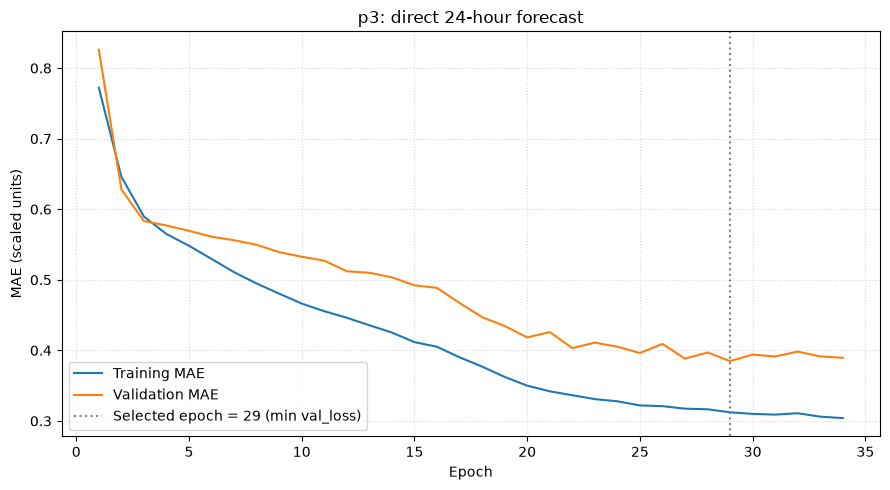

Selected epoch: 29 (minimum validation MSE)
Training MAE:   0.3122
Validation MAE: 0.3848
Training time: 00:00:36


E0000 00:00:1792787019.955650    1267 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


                 val_mae_hour_1  val_mae_hour_24  val_mae_overall_24h
forecast_method                                                      
recursive                0.0764           0.5196               0.4871
direct                   0.2902           0.3665               0.3848


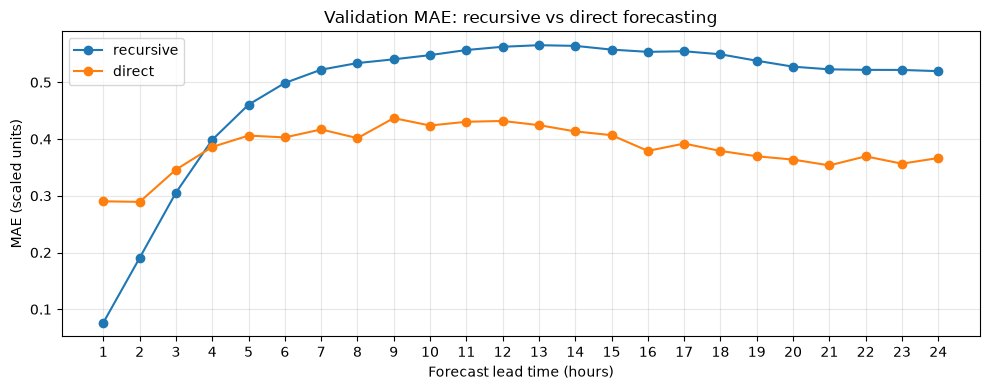

In [64]:
## _1. Experiment settings and storage.

p3_lookback_hours = 168
p3_forecast_hours = 24

p3_experiment_config = {
    "recursive": {
        "title": "p3: recursive 24-hour forecast",
        "training_horizon": 1,
    },
    "direct": {
        "title": "p3: direct 24-hour forecast",
        "training_horizon": 24,
    },
}

p3_models = {}
p3_histories = {}
p3_training_summaries = {}
p3_validation_predictions = {}

# ## _Keep the global dictionary used by train_and_validate.
# if "results" not in globals():
#     results = {}


## _2. Build each training dataset once.

p3_datasets = {}

for training_horizon in (1, 24):
    (
        X_train_current,
        y_train_current,
        X_val_current,
        y_val_current,
        X_test_current,
        y_test_current,
    ) = build_datasets(
        lookback=   p3_lookback_hours,
        horizon=    training_horizon,
    )

    p3_datasets[training_horizon] = {
        "X_train": X_train_current,
        "y_train": y_train_current,
        "X_val": X_val_current,
        "y_val": y_val_current,
    }


## _3. Train both models and preserve their histories.
## _Datasets are passed explicitly: no dependency on global X_train or X_val.

for method, experiment_config in p3_experiment_config.items():
    keras.utils.set_random_seed(random_seed)

    training_horizon = experiment_config["training_horizon"]
    training_data = p3_datasets[training_horizon]

    current_model = make_baseline_model(
        lookback=p3_lookback_hours,
        horizon=training_horizon,
    )

    training_history, training_summary = train_and_validate(
        model=current_model,
        X_train=training_data["X_train"],
        y_train=training_data["y_train"],
        X_val=training_data["X_val"],
        y_val=training_data["y_val"],
        title=experiment_config["title"],
        epochs=50,
        batch_size=64,
        optimizer="Adam",
        lr_schedule=1e-3,
        clipnorm=1.0,
        patience=5,
        plot_scaled_curves=True,
        return_history=True,
        verbose=0,
    )

    p3_models[method] = current_model
    p3_histories[method] = training_history
    p3_training_summaries[method] = dict(training_summary)


## _4. Recursive forecast: slide each input window forward by one hour.
## _Append only predictions; never append actual future observations.

def recursive_forecast(
    one_step_model,
    input_windows,
    forecast_hours=24,
    batch_size=512,
):
    rolling_windows = np.array(input_windows, copy=True)

    if rolling_windows.ndim != 3 or rolling_windows.shape[-1] != 1:
        raise ValueError(
            "Expected input_windows with shape (n_windows, lookback, 1)."
        )

    forecast_predictions = np.empty(
        (len(rolling_windows), forecast_hours),
        dtype=rolling_windows.dtype,
    )

    for forecast_step in range(forecast_hours):
        next_hour_predictions = np.asarray(
            one_step_model.predict(
                rolling_windows,
                batch_size=batch_size,
                verbose=0,
            )
        )

        expected_shape = (len(rolling_windows), 1)

        if next_hour_predictions.shape != expected_shape:
            raise ValueError(
                f"One-step model must output {expected_shape}; "
                f"received {next_hour_predictions.shape}."
            )

        forecast_predictions[:, forecast_step] = next_hour_predictions[:, 0]

        rolling_windows = np.concatenate(
            [
                rolling_windows[:, 1:, :],
                next_hour_predictions[:, :, None],
            ],
            axis=1,
        )

    return forecast_predictions


## _5. Use the 24-hour validation dataset for BOTH forecast methods.
## _All errors remain in scaled units.

p3_X_val = p3_datasets[24]["X_val"]
p3_y_val_scaled = np.asarray(
    p3_datasets[24]["y_val"]
).reshape(len(p3_X_val), p3_forecast_hours)

p3_validation_predictions["recursive"] = recursive_forecast(
    one_step_model=p3_models["recursive"],
    input_windows=p3_X_val,
    forecast_hours=p3_forecast_hours,
)

p3_validation_predictions["direct"] = np.asarray(
    p3_models["direct"].predict(p3_X_val, verbose=0)
)


## _6. Calculate errors and update the main results dictionary.
## _Training metrics and forecast metrics are stored under separate keys.

p3_validation_errors = {}

for method, predictions in p3_validation_predictions.items():
    if predictions.shape != p3_y_val_scaled.shape:
        raise ValueError(
            f"{method}: predictions {predictions.shape} do not match "
            f"targets {p3_y_val_scaled.shape}."
        )

    absolute_errors = np.abs(p3_y_val_scaled - predictions)
    p3_validation_errors[method] = absolute_errors

    forecast_summary = {
        "val_mae_hour_1": float(absolute_errors[:, 0].mean()),
        "val_mae_hour_24": float(absolute_errors[:, 23].mean()),
        "val_mae_overall_24h": float(absolute_errors.mean()),
        "val_mae_by_lead_hour": {
            hour: float(mae)
            for hour, mae in enumerate(
                absolute_errors.mean(axis=0),
                start=1,
            )
        },
        "n_validation_windows": len(p3_X_val),
        "units": "scaled",
    }

    experiment_title = p3_experiment_config[method]["title"]

    results2[experiment_title] = {
        "method": method,
        "lookback_hours": p3_lookback_hours,
        "training_horizon": p3_experiment_config[method]["training_horizon"],
        "forecast_hours": p3_forecast_hours,
        "training_summary": p3_training_summaries[method],
        "training_history": dict(p3_histories[method].history),
        "forecast_validation": forecast_summary,
    }

    H = p3_histories[method].history

    val_loss = np.asarray(H["val_loss"])
    mae = np.asarray(H["mae"])
    val_mae = np.asarray(H["val_mae"])
    epochs = np.arange(1, len(mae) + 1)

    # Select epoch by minimum validation MSE (not minimum MAE)
    best_idx = int(np.argmin(val_loss))
    best_epoch = best_idx + 1

    # Record MAE at the selected epoch
    summary = {
        "selected_epoch": best_epoch,
        "val_mae_at_min_valloss": float(val_mae[best_idx]),
        "train_mae_at_sel": float(mae[best_idx]),
        "val_loss": float(val_loss[best_idx]),
        "units": "scaled",
    }
    results[experiment_title] = summary


## _7. Report hour 1, hour 24, and overall MAE.
## _Keep full precision in stored results; round only for display.

p3_mae_report = (
    pd.DataFrame.from_dict(
        {
            method: results2[config["title"]]["forecast_validation"]
            for method, config in p3_experiment_config.items()
        },
        orient="index",
    )
    .rename_axis("forecast_method")
    .loc[:, [
        "val_mae_hour_1",
        "val_mae_hour_24",
        "val_mae_overall_24h",
    ]]
)

print(p3_mae_report.round(4))


## _8. Plot scaled MAE at each forecast hour.

p3_mae_by_lead_hour = pd.DataFrame(
    {
        method: absolute_errors.mean(axis=0)
        for method, absolute_errors in p3_validation_errors.items()
    },
    index=pd.Index(
        range(1, p3_forecast_hours + 1),
        name="forecast_hour",
    ),
)

ax = p3_mae_by_lead_hour.plot(
    marker="o",
    figsize=(10, 4),
)

ax.set(
    title="Validation MAE: recursive vs direct forecasting",
    xlabel="Forecast lead time (hours)",
    ylabel="MAE (scaled units)",
    xticks=range(1, p3_forecast_hours + 1),
)

ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

---

# ---


In [69]:
p3_mae_report.query

,val_mae_hour_1,val_mae_hour_24,val_mae_overall_24h
forecast_method,,,
recursive,0.076403,0.519618,0.487124
direct,0.290245,0.366499,0.384835


In [ ]:
# p3_histories['recursive'].history['val_loss']

[0.3420775234699249,
 0.257366806268692,
 0.1840612292289734,
 0.09393951296806335,
 0.07597650587558746,
 0.05162939429283142,
 0.03898709639906883,
 0.030667953193187714,
 0.028777070343494415,
 0.025085346773266792,
 0.021806785836815834,
 0.020125821232795715,
 0.01969298906624317,
 0.018124165013432503,
 0.01659458689391613,
 0.01561840157955885,
 0.015403471887111664,
 0.017162030562758446,
 0.016162831336259842,
 0.014683783054351807,
 0.016227856278419495,
 0.015197321772575378,
 0.013862145133316517,
 0.013670897111296654,
 0.01429636962711811,
 0.01349978893995285,
 0.014560725539922714,
 0.015191629528999329,
 0.013792400248348713,
 0.013725987635552883,
 0.01616174541413784]

In [66]:
print_results()

Experiment                               Val MAE    Epoch
----------------------------------------------------------
p3: recursive 24-hour forecast            0.0759       26
p3: direct 24-hour forecast               0.3848       29

MAE is in scaled units; epoch selected by minimum validation MSE.


In [67]:
results

{'p3: recursive 24-hour forecast': {'selected_epoch': 26,
  'val_mae_at_min_valloss': 0.07585766911506653,
  'train_mae_at_sel': 0.11760718375444412,
  'val_loss': 0.01349978893995285,
  'units': 'scaled'},
 'p3: direct 24-hour forecast': {'selected_epoch': 29,
  'val_mae_at_min_valloss': 0.38483521342277527,
  'train_mae_at_sel': 0.3122252821922302,
  'val_loss': 0.22998559474945068,
  'units': 'scaled'}}

In [68]:
float(results['p1-C: 168hr -> 24 hr']['val_mae_at_min_valloss'])

KeyError: 'p1-C: 168hr -> 24 hr'